In [1]:
import sys
import numpy as np

print("Python version:", sys.version)
print("NumPy version:", np.__version__)
print("Environment ready.")

Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
NumPy version: 2.1.3
Environment ready.


In [2]:
%pip install -q deepchecks==0.19.1

In [3]:
import numpy as np

if not hasattr(np, "Inf"):
    np.Inf = np.inf

print("NumPy compatibility check completed.")

NumPy compatibility check completed.


In [4]:
import deepchecks
from deepchecks.tabular import Dataset
from deepchecks.tabular.suites import data_integrity

print("Deepchecks version:", deepchecks.__version__)
print("Deepchecks imports successful.")

/usr/local/lib/python3.13/dist-packages/deepchecks/core/serialization/dataframe/html.py:16: UserWarning:

pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.



Deepchecks version: 0.19.1
Deepchecks imports successful.


In [5]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)
df = iris.frame.copy()

print("Dataset shape:", df.shape)
print("\nFirst five rows:")
display(df.head())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Dataset shape: (150, 5)

First five rows:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0



Missing values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
dtype: int64

Duplicate rows: 1


In [6]:
dirty_df = df.copy()

# Introduce one missing value
dirty_df.loc[0, "sepal length (cm)"] = np.nan

# Add one duplicate record
dirty_df = pd.concat(
    [dirty_df, dirty_df.iloc[[1]]],
    ignore_index=True
)

print("Original rows:", len(df))
print("Modified rows:", len(dirty_df))
print("Missing values:", dirty_df.isnull().sum().sum())
print("Duplicate rows:", dirty_df.duplicated().sum())

Original rows: 150
Modified rows: 151
Missing values: 1
Duplicate rows: 2


In [7]:
dirty_dataset = Dataset(
    dirty_df,
    label="target"
)

integrity_suite = data_integrity()
integrity_result = integrity_suite.run(dirty_dataset)

integrity_result.show()
integrity_result.save_as_html("data_integrity_report.html")

print("Data integrity report generated.")

deepchecks - WARNING - It is recommended to initialize Dataset with categorical features by doing "Dataset(df, cat_features=categorical_list)". No categorical features were passed, therefore heuristically inferring categorical features in the data. 0 categorical features were inferred.


<!--
 ~ ----------------------------------------------------------------------------
 ~ Copyright (C) 2021-2023 Deepchecks (https://www.deepchecks.com)
 ~
 ~ This file is part of Deepchecks.
 ~ Deepchecks is distributed under the terms of the GNU Affero General
 ~ Public License (version 3 or later).
 ~ You should have received a copy of the GNU Affero General Public License
 ~ along with Deepchecks. If not, see .
 ~ ----------------------------------------------------------------------------
 ~
-->
<!DOCTYPE html>
 
 
 
 Data Integrity Suite

Data integrity report generated.


In [8]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["target"])
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

train_df = X_train.copy()
train_df["target"] = y_train

test_df = X_test.copy()
test_df["target"] = y_test

print("Training records:", len(train_df))
print("Testing records:", len(test_df))

Training records: 120
Testing records: 30


In [9]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Model accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("\nClassification report:")
print(classification_report(y_test, y_pred))

Model accuracy: 0.9

Classification report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       0.82      0.90      0.86        10
           2       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30



In [10]:
from deepchecks.tabular.suites import train_test_validation

train_dataset = Dataset(train_df, label="target")
test_dataset = Dataset(test_df, label="target")

validation_result = train_test_validation().run(
    train_dataset=train_dataset,
    test_dataset=test_dataset,
    model=model
)

validation_result.show()
validation_result.save_as_html("train_test_validation_report.html")

print("Train-test validation completed.")

deepchecks - WARNING - It is recommended to initialize Dataset with categorical features by doing "Dataset(df, cat_features=categorical_list)". No categorical features were passed, therefore heuristically inferring categorical features in the data. 0 categorical features were inferred.
deepchecks - WARNING - It is recommended to initialize Dataset with categorical features by doing "Dataset(df, cat_features=categorical_list)". No categorical features were passed, therefore heuristically inferring categorical features in the data. 0 categorical features were inferred.


/usr/local/lib/python3.13/dist-packages/deepchecks/tabular/checks/train_test_validation/train_test_samples_mix.py:85: FutureWarning:

DataFrame.applymap has been deprecated. Use DataFrame.map instead.



<!--
 ~ ----------------------------------------------------------------------------
 ~ Copyright (C) 2021-2023 Deepchecks (https://www.deepchecks.com)
 ~
 ~ This file is part of Deepchecks.
 ~ Deepchecks is distributed under the terms of the GNU Affero General
 ~ Public License (version 3 or later).
 ~ You should have received a copy of the GNU Affero General Public License
 ~ along with Deepchecks. If not, see .
 ~ ----------------------------------------------------------------------------
 ~
-->
<!DOCTYPE html>
 
 
 
 Train Test Validation Suite

Train-test validation completed.


In [11]:
from deepchecks.tabular.suites import model_evaluation

evaluation_result = model_evaluation().run(
    train_dataset=train_dataset,
    test_dataset=test_dataset,
    model=model
)

evaluation_result.show()
evaluation_result.save_as_html("model_evaluation_report.html")

print("Model evaluation completed.")

/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py:960: UserWarning:

Scoring failed. The score on this train-test partition for these parameters will be set to nan. Details: 
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py", line 949, in _score
    scores = scorer(estimator, X_test, y_test, **score_params)
  File "/usr/local/lib/python3.13/dist-packages/deepchecks/utils/abstracts/weak_segment_abstract.py", line 336, in neg_worst_segment_score
    return -get_worst_leaf_filter(clf.tree_)[0]
            ~~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/deepchecks/utils/abstracts/weak_segment_abstract.py", line 321, in get_worst_leaf_filter
    leaves_filters = convert_tree_leaves_into_filters(tree, features_for_segment)
  File "/usr/local/lib/python3.13/dist-packages/deepchecks/utils/performance/partition.py", line 283, in convert_tree_leaves_into_filters


<!--
 ~ ----------------------------------------------------------------------------
 ~ Copyright (C) 2021-2023 Deepchecks (https://www.deepchecks.com)
 ~
 ~ This file is part of Deepchecks.
 ~ Deepchecks is distributed under the terms of the GNU Affero General
 ~ Public License (version 3 or later).
 ~ You should have received a copy of the GNU Affero General Public License
 ~ along with Deepchecks. If not, see .
 ~ ----------------------------------------------------------------------------
 ~
-->
<!DOCTYPE html>
 
 
 
 Model Evaluation Suite

Model evaluation completed.


In [12]:
drift_df = test_df.copy()

drift_df["sepal length (cm)"] += 1.5
drift_df["petal length (cm)"] += 1.0

drift_dataset = Dataset(drift_df, label="target")

drift_result = train_test_validation().run(
    train_dataset=train_dataset,
    test_dataset=drift_dataset,
    model=model
)

drift_result.show()
drift_result.save_as_html("data_drift_report.html")

print("Simulated data drift analysis completed.")

deepchecks - WARNING - It is recommended to initialize Dataset with categorical features by doing "Dataset(df, cat_features=categorical_list)". No categorical features were passed, therefore heuristically inferring categorical features in the data. 0 categorical features were inferred.


/usr/local/lib/python3.13/dist-packages/deepchecks/tabular/checks/train_test_validation/train_test_samples_mix.py:85: FutureWarning:

DataFrame.applymap has been deprecated. Use DataFrame.map instead.



<!--
 ~ ----------------------------------------------------------------------------
 ~ Copyright (C) 2021-2023 Deepchecks (https://www.deepchecks.com)
 ~
 ~ This file is part of Deepchecks.
 ~ Deepchecks is distributed under the terms of the GNU Affero General
 ~ Public License (version 3 or later).
 ~ You should have received a copy of the GNU Affero General Public License
 ~ along with Deepchecks. If not, see .
 ~ ----------------------------------------------------------------------------
 ~
-->
<!DOCTYPE html>
 
 
 
 Train Test Validation Suite

Simulated data drift analysis completed.


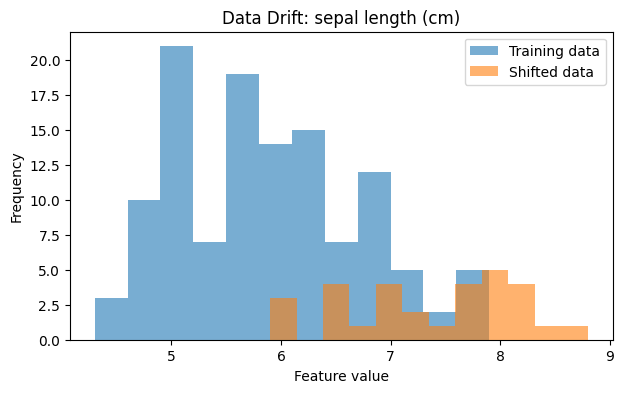

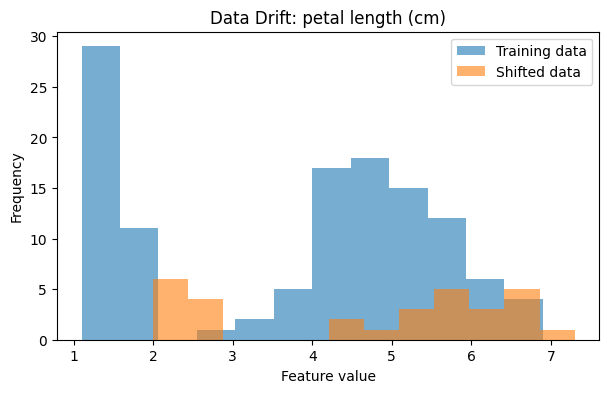

In [13]:
for feature in ["sepal length (cm)", "petal length (cm)"]:
    plt.figure(figsize=(7, 4))

    plt.hist(
        X_train[feature],
        bins=12,
        alpha=0.6,
        label="Training data"
    )

    plt.hist(
        drift_df[feature],
        bins=12,
        alpha=0.6,
        label="Shifted data"
    )

    plt.title("Data Drift: " + feature)
    plt.xlabel("Feature value")
    plt.ylabel("Frequency")
    plt.legend()
    plt.show()

In [14]:
import joblib
import hashlib

joblib.dump(model, "iris_model.pkl")
loaded_model = joblib.load("iris_model.pkl")

assert np.array_equal(
    model.predict(X_test),
    loaded_model.predict(X_test)
), "Model integrity verification failed"

with open("iris_model.pkl", "rb") as f:
    checksum = hashlib.sha256(f.read()).hexdigest()

print("Model integrity verified.")
print("SHA-256 checksum:", checksum)

Model integrity verified.
SHA-256 checksum: 2ba6d07c5bb89dedd1cf68065c402c23bd0d1fdd48d08c0c520f42d151f06fc3


In [15]:
import os
import zipfile
from google.colab import files

report_files = [
    "data_integrity_report.html",
    "train_test_validation_report.html",
    "model_evaluation_report.html",
    "data_drift_report.html",
    "iris_model.pkl"
]

with zipfile.ZipFile(
    "deepchecks_experiment_results.zip",
    "w",
    zipfile.ZIP_DEFLATED
) as zf:
    for filename in report_files:
        if os.path.exists(filename):
            zf.write(filename)

files.download("deepchecks_experiment_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>